In [2]:
import feedparser
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import spacy
from PIL import Image
import numpy as np
import re
import unicodedata
import networkx as nx
from collections import Counter

In [7]:
# Load the French & English language model
nlp = spacy.load('fr_core_news_sm')
nlp2 = spacy.load('en_core_web_sm')

# Dictionary of RSS feeds
rss_feeds = {
    "France24": "https://www.france24.com/fr/rss",
    "FranceInfo": "https://www.francetvinfo.fr/titres.rss",
    "Le Figaro": "http://www.lefigaro.fr/rss/figaro_actualites.xml",
    "Le Monde": "https://www.lemonde.fr/rss/une.xml",
    "CourrierInternational":"https://www.courrierinternational.com/feed/rubrique/france/rss.xml",
    "RadioFrance":"https://www.radiofrance.fr/rss/politique",
    "L'Equipe":"https://dwh.lequipe.fr/api/edito/rss?path=/"

}

# Colors for the word clouds
colors = {
    "France24": 'Blues',
    "FranceInfo": 'Greens',
    "Le Figaro": 'Purples',
    "Le Monde": 'Oranges',
    "CourrierInternational":'Reds',
    "RadioFrance":'Reds',
    "L'Equipe":'Reds'
}

# Load the image of France map
france_mask = np.array(Image.open("france_map.png"))

In [4]:
rss_feeds = {
    "figaro":"https://www.lefigaro.fr/rss/figaro_actualites.xml",
    "libe":"https://www.liberation.fr/arc/outboundfeeds/rss/?outputType=xml",
    "parisien":"https://feeds.leparisien.fr/leparisien/rss",
    "franceinfo":"https://www.francetvinfo.fr/titres.rss",
    "lemonde":"https://www.lemonde.fr/rss/en_continu.xml",
    "express":"https://www.lexpress.fr/arc/outboundfeeds/rss/alaune.xml",
    "ouestfrance":"https://www.ouest-france.fr/rss/une",
    "dna":"http://atlasflux.saynete.net/atlas_des_flux_rss_fra_dedie_dna.htm",
    "sudouest":"http://atlasflux.saynete.net/atlas_des_flux_rss_fra_dedie_sudouest.htm",
    "france24":"https://www.france24.com/fr/rss",
    "afp":"https://www.afp.com/fr/actus/afp_actualite/792,31,9,7,33/feed",
    "europe1":"https://www.europe1.fr/rss/actualites.xml",
    "france3":"http://atlasflux.saynete.net/atlas_des_flux_rss_fra_dedie_francetrois.htm"
}

In [8]:
def display_feed_status(rss_feeds):
    """
    Check if the RSS feeds can be read and display their status.
    
    Args:
    - rss_feeds (dict): A dictionary where keys are feed names and values are URLs of the RSS feeds.
    """
    for name, url in rss_feeds.items():
        # Parse the RSS feed
        feed = feedparser.parse(url)
        
        if feed.bozo:
            print(f"Unable to read feed: {name} ({url})")
        else:
            print(f"Successfully read feed: {name} ({feed.feed.title})")

if __name__ == "__main__":

    # Display the feed status
    display_feed_status(rss_feeds)

Successfully read feed: France24 (France 24 - Infos, news & actualités - L'information internationale en direct)
Successfully read feed: FranceInfo (Franceinfo - Les Titres)
Successfully read feed: Le Figaro (Le Figaro - Actualité en direct et informations en continu)
Successfully read feed: Le Monde (Le Monde.fr - Actualités et Infos en France et dans le monde)
Successfully read feed: CourrierInternational (Courrier international - Actualités France et Monde, vidéos, infographies)
Successfully read feed: RadioFrance (Politique : Tous les podcasts et l'actualité politique en France)
Successfully read feed: L'Equipe (L'Équipe - L'actualité du sport en continu.)


http://atlasflux.saynete.net/atlas_des_flux_rss_fra_dedie_afp.htm

In [9]:
def display_feed_titles(feed):
    # Parse the RSS feed
    feed = feedparser.parse(url)
    
    # Display the feed titles
    print(f"Feed Title: {feed.feed.title}")
    print("Articles:\n")
    for entry in feed.entries:
        print(f"Title: {entry.title}")
        print(f"Link: {entry.link}")
        print("\n")

if __name__ == "__main__":
    # URL of Franceinfo RSS feed
    franceinfo_rss_url = "https://www.francetvinfo.fr/titres.rss"

    # Display the feed titles
    display_feed_titles(rss_feeds)

NameError: name 'url' is not defined

In [10]:
def fetch_rss_feed(url):
    # Parse the RSS feed
    feed = feedparser.parse(url)
    return feed

def get_titles_from_feed(feed):
    # Extract titles from the feed
    titles = [entry.title for entry in feed.entries]
    return titles

def remove_accents(text):
    return ''.join(c for c in unicodedata.normalize('NFKD', text) if not unicodedata.combining(c))

def filter_nouns(text):
    # Remove special characters and digits (but not numbers) from the text
    text = re.sub(r'\b\w\b','', text)
    text = re.sub(r'\bEn direct\b','', text)
    text = re.sub(r'[^a-zA-Z0-9À-ÿ\s]', ' ', text)
    text = remove_accents(text)

    # Filter out only common nouns from the text
    doc = nlp(text.lower())

    nouns = [token.text for token in doc if token.pos_ in ['NOUN', 'PROPN', 'ADJ']]
    #nouns = [token.text for token in doc if token.pos_ == 'NOUN']
    return ' '.join(nouns)

In [11]:
def get_top_words(filtered_texts, max_words=50):
    """
    Get the top words by occurrence from the filtered texts.
    
    Args:
    - filtered_texts (dict): A dictionary where keys are source names and values are lists of filtered texts.
    - max_words (int): Maximum number of words to return.
    
    Returns:
    - list: List of tuples containing words and their frequencies.
    """
    all_words = []
    for name, texts in filtered_texts.items():
        for text in texts:
            all_words.extend(filter_nouns_and_entities(text))
    
    word_freq = Counter(all_words)
    return word_freq.most_common(max_words)

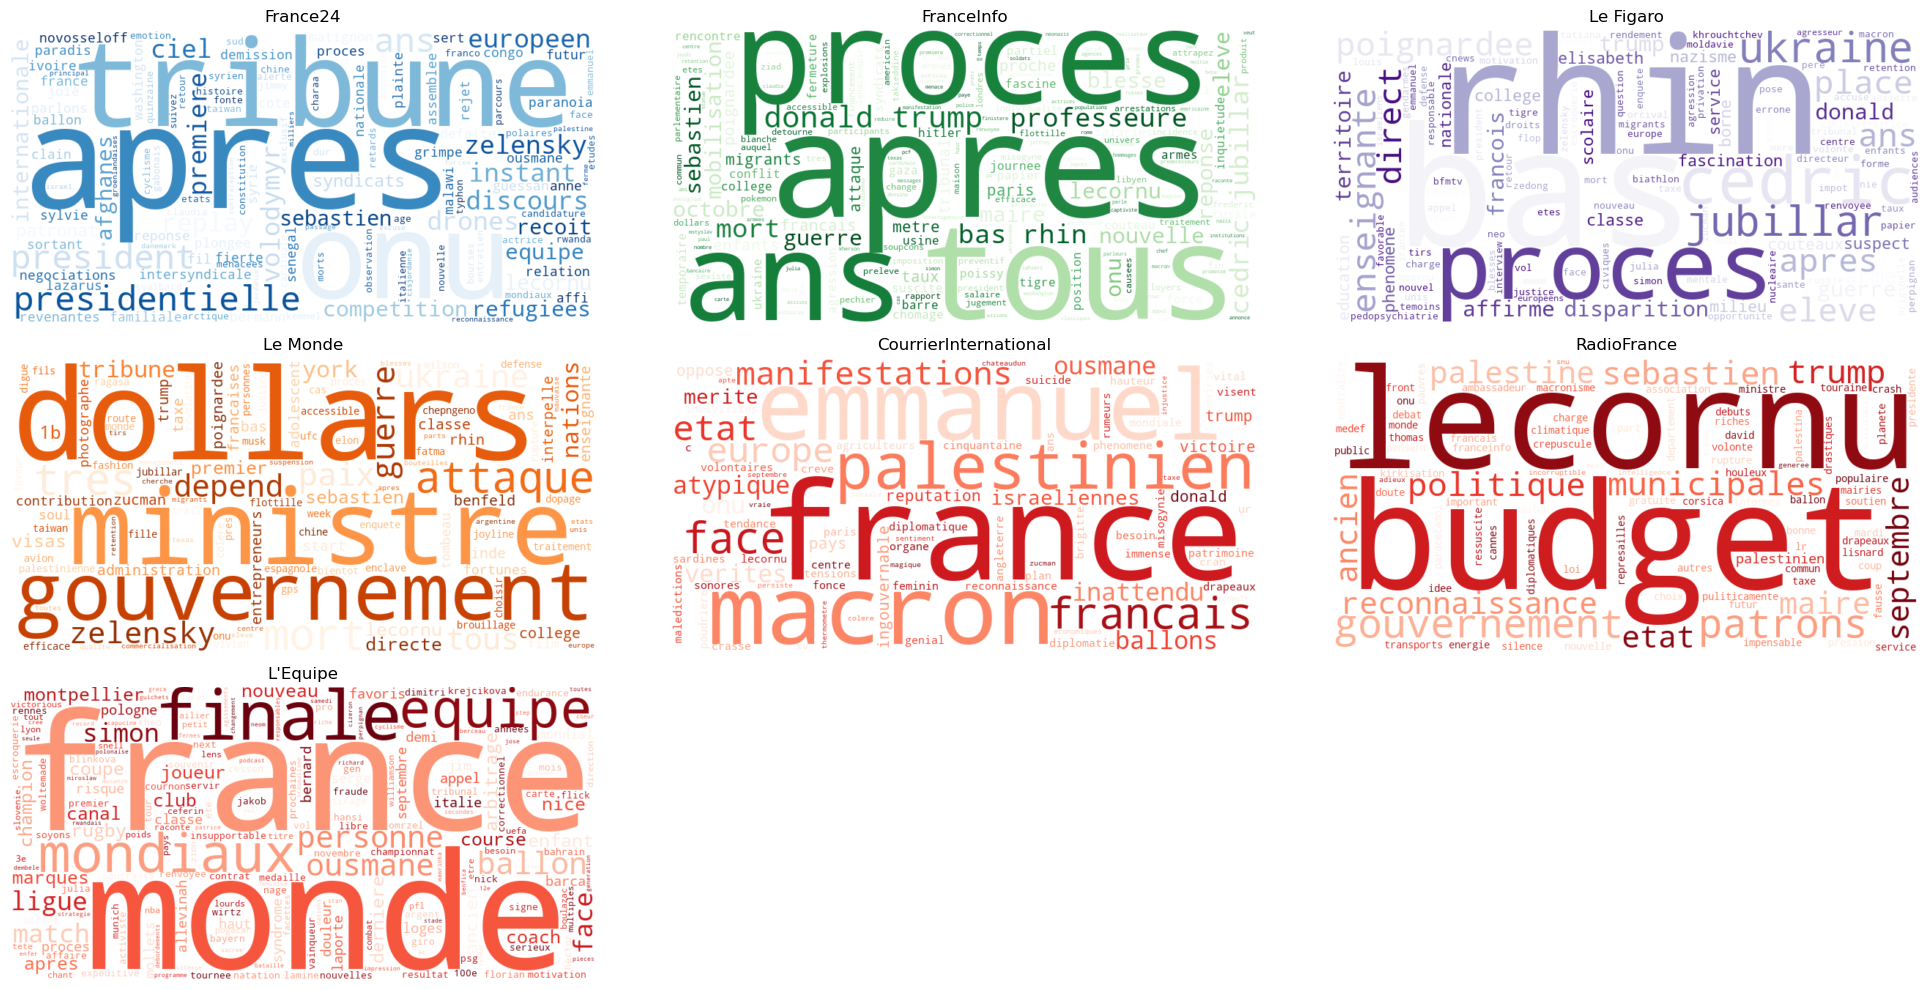

In [12]:
def generate_word_cloud(text, colormap):
    # Generate a word cloud with a specific colormap
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap=colormap).generate(text)
    return wordcloud

def display_word_clouds(wordclouds):
    # Display the word clouds using matplotlib
    plt.figure(figsize=(20, 10))
    for i, (title, wordcloud) in enumerate(wordclouds.items(), 1):
        plt.subplot(3, 3, i)
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    wordclouds = {}

    for name, url in rss_feeds.items():
        # Fetch the RSS feed
        rss_feed = fetch_rss_feed(url)

        # Get the titles from the feed
        titles = get_titles_from_feed(rss_feed)

        # Combine all titles into a single string
        combined_titles = ' '.join(titles)

        # Filter out only common nouns from the combined titles
        filtered_text = filter_nouns(combined_titles)

        # Ensure there is at least one word to generate the word cloud
        if filtered_text.strip():
            # Generate the word cloud with the specified color
            wordcloud = generate_word_cloud(filtered_text, colors[name])

            # Store the word cloud
            wordclouds[name] = wordcloud

    # Display the word clouds
    display_word_clouds(wordclouds)

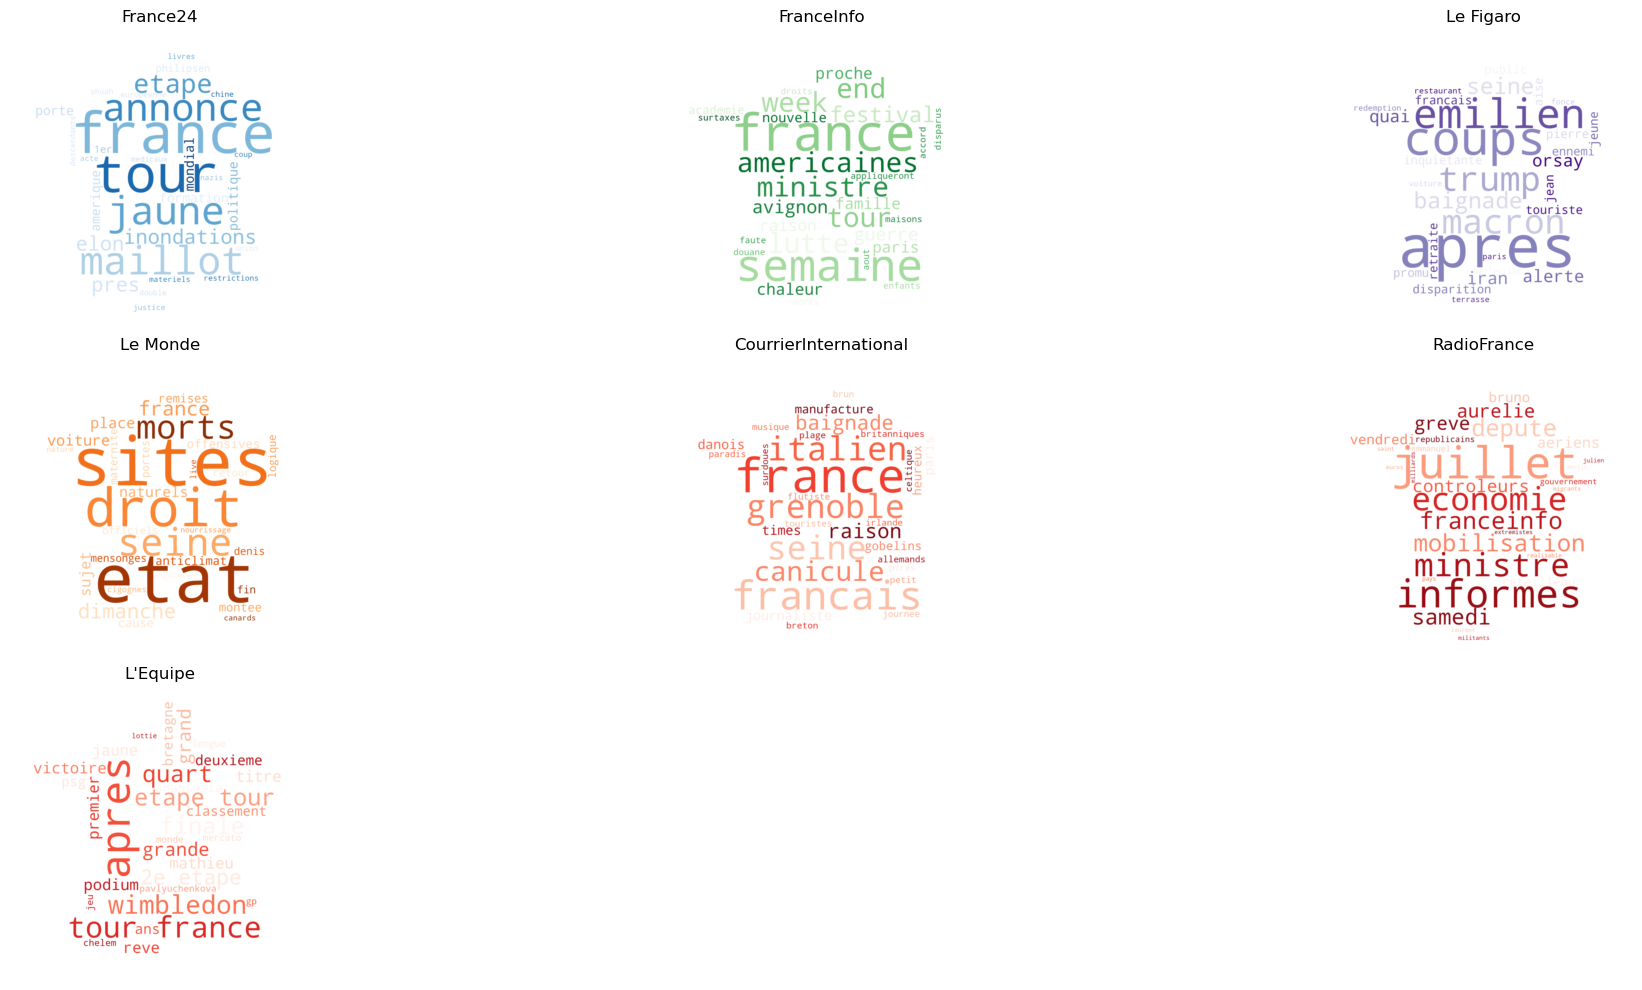

In [28]:
def generate_word_cloud(text, colormap, max_words=100):
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        mask=france_mask,
        colormap=colormap,
        max_words=max_words
    ).generate(text)
    return wordcloud



def display_word_clouds(wordclouds):
    # Display the word clouds using matplotlib
    plt.figure(figsize=(20, 10))
    for i, (title, wordcloud) in enumerate(wordclouds.items(), 1):
        plt.subplot(3, 3, i)
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    wordclouds = {}

    for name, url in rss_feeds.items():
        # Fetch the RSS feed
        rss_feed = fetch_rss_feed(url)

        # Get the titles from the feed
        titles = get_titles_from_feed(rss_feed)

        # Combine all titles into a single string
        combined_titles = ' '.join(titles)

        # Filter out only common nouns from the combined titles
        filtered_text = filter_nouns(combined_titles)

        # Ensure there is at least one word to generate the word cloud
        if filtered_text.strip():
            # Generate the word cloud with the specified color
            wordcloud = generate_word_cloud(filtered_text, colors[name], max_words=30)

            # Store the word cloud
            wordclouds[name] = wordcloud

    # Display the word clouds
    display_word_clouds(wordclouds)

iran quai orsay alerte disparition inquietante jeune touriste francais jean pierre promu ennemi public retraite aise redemption paris voiture fonce terrasse restaurant belleville personnes blessees algerie emmanuel prisonnier piege enferme presidentielle insoumise mathilde panot raphael autre macron possible petits cailloux presidentiels semes macron apres tour france pouvoir pogacar vingegaard places classement general apres etape inauguree jour fete nationale baignade seine provocation tiktok peine inauguree fermee baignade seine dimanche raison intemperies changement ton reunions mois apres arrivee bernard fontana transforme negociations attendues doha rencontre netanyahou trump groupe arme palestinien armee israelienne afrique continent oublie temps apres elimination coups emilien etudes coups recordman emilien elimine jeu tf1 apres participations coups romain candidat champion emilien secrets castel gandolfo residence papes argent marseille influenceuse victime violent home
dispar

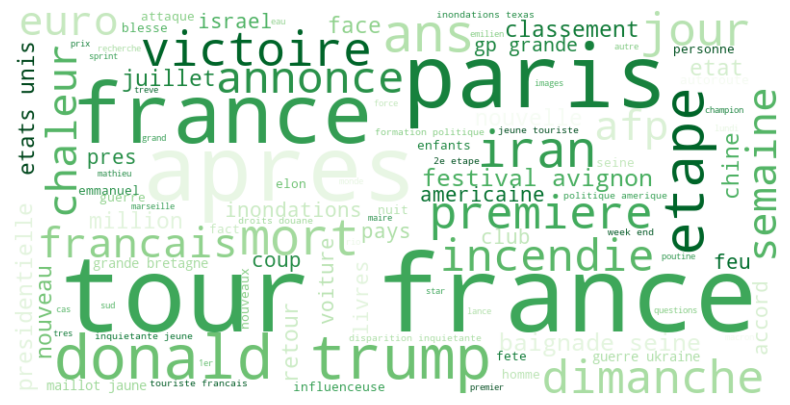

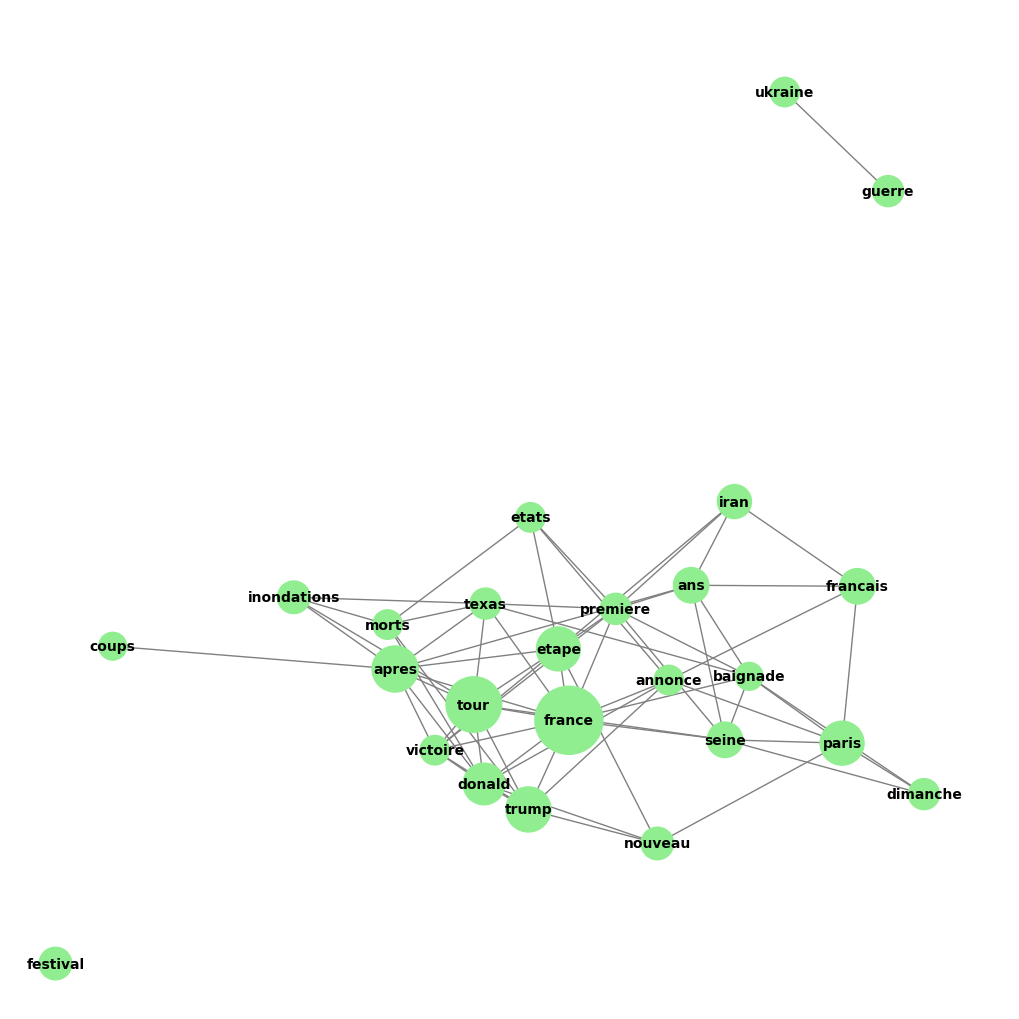

In [13]:
def generate_global_word_cloud(filtered_texts, colors, max_words=50):
    """
    Generate a global word cloud from filtered texts.

    Args:
    - filtered_texts (dict): A dictionary where keys are source names and values are filtered texts.
    - colors (dict): A dictionary where keys are source names and values are colors for word clouds.
    - max_words (int, optional): Maximum number of words to display in the word cloud. Default is 100.

    Returns:
    - WordCloud: A WordCloud object representing the global word cloud.
    """
    combined_text = ' '.join(filtered_texts.values())
    wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=max_words, colormap='Greens').generate(combined_text)
    
    return wordcloud

def display_word_cloud(wordcloud):
    # Display the word cloud using matplotlib
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.show()

def build_word_graph(filtered_texts, max_words=50, window_size=3):
    """
    Build a word graph from filtered texts, linking words that appear close to each other.

    Args:
    - filtered_texts (dict): A dictionary where keys are source names and values are filtered texts.
    - max_words (int): Maximum number of words to include in the graph.
    - window_size (int): Number of words apart to consider linking.

    Returns:
    - networkx.Graph: A graph where nodes are words and edges represent proximity in text.
    """
    combined_text = ' '.join(filtered_texts.values())
    words = combined_text.split()
    
    # Count word frequencies
    word_freq = {}
    for word in words:
        word_freq[word] = word_freq.get(word, 0) + 1

    # Sort words by frequency and keep the top `max_words`
    sorted_words = sorted(word_freq.items(), key=lambda item: item[1], reverse=True)[:max_words]
    top_words = {word for word, freq in sorted_words}

    # Build the graph
    G = nx.Graph()
    for word in top_words:
        G.add_node(word, size=word_freq[word])

    # Add edges based on proximity in text, but not self-loops
    for i in range(len(words) - window_size):
        if words[i] in top_words:
            for j in range(1, window_size):
                if words[i + j] in top_words and words[i] != words[i + j]:
                    G.add_edge(words[i], words[i + j])

    return G

def display_word_graph(G):
    # Display the word graph using matplotlib
    plt.figure(figsize=(10, 10))
    
    # Calculate positions with the spring layout, prioritizing higher frequency words at the center
    pos = nx.spring_layout(G, k=0.5, weight=None, iterations=50, seed=42)
    
    # Draw nodes with sizes based on word frequencies
    node_sizes = [G.nodes[node]['size'] * 50 for node in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color='lightgreen', edge_color='gray', node_size=node_sizes, font_size=10, font_weight='bold')
    
    plt.show()

if __name__ == "__main__":
    filtered_texts = {}

    for name, url in rss_feeds.items():
        # Fetch the RSS feed
        rss_feed = fetch_rss_feed(url)
        #print(rss_feed)
        # Get the titles from the feed
        titles = get_titles_from_feed(rss_feed)
        #print(titles)
        # Combine titles into a single string
        combined_titles = ' '.join(titles)
        #print(combined_titles)
        # Filter out only common nouns from the combined titles
        filtered_text = filter_nouns(combined_titles)
        # Store the filtered text for this source
        filtered_texts[name] = filtered_text
        print(filtered_text)

    # Get the top 50 words by occurrence
    #top_words = get_top_words(filtered_text, max_words=50)
    
    # Generate the global word cloud with the specified number of words
    wordcloud = generate_global_word_cloud(filtered_texts, colors, max_words=100)
    display_word_cloud(wordcloud)

    # Build and display the word graph
    word_graph = build_word_graph(filtered_texts, max_words=25, window_size=3)
    display_word_graph(word_graph)

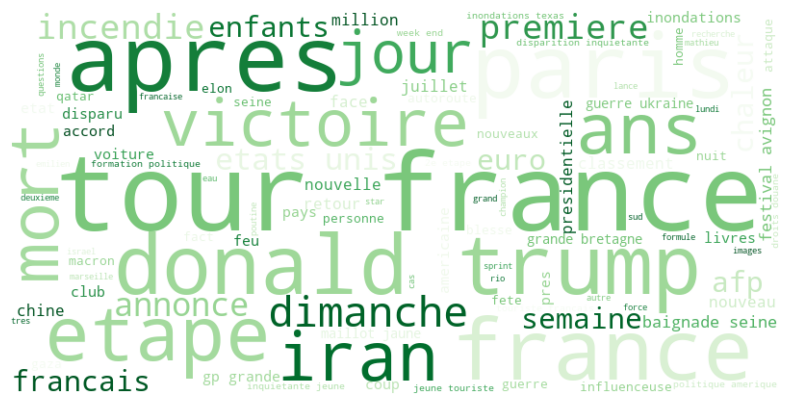

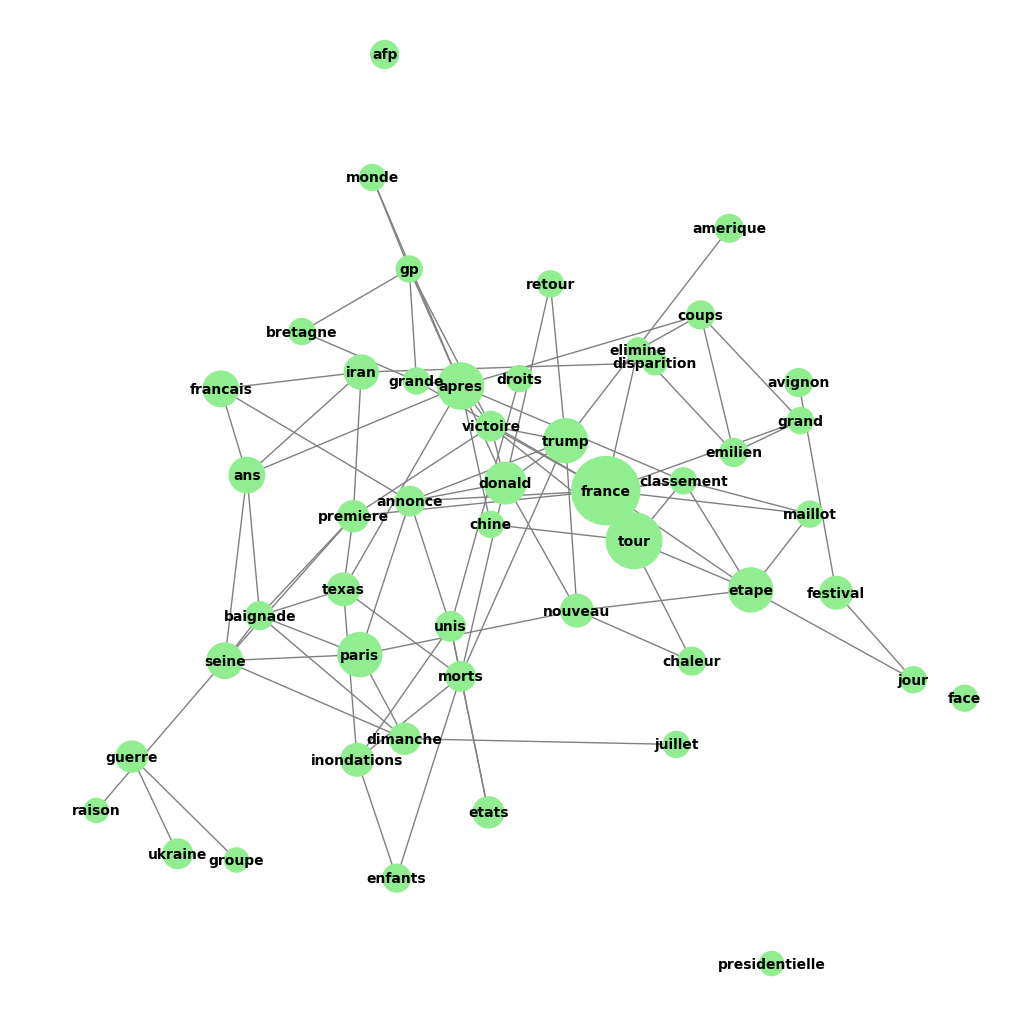

In [14]:
def generate_word_cloud(text, colormap, max_words=100):
    # Generate a word cloud with a specific colormap and max number of words
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap=colormap, max_words=max_words).generate(text)
    return wordcloud

def generate_global_word_cloud(filtered_texts, colors, max_words=100):
    """
    Generate a global word cloud from filtered texts.

    Args:
    - filtered_texts (dict): A dictionary where keys are source names and values are filtered texts.
    - colors (dict): A dictionary where keys are source names and values are colors for word clouds.
    - max_words (int, optional): Maximum number of words to display in the word cloud. Default is 100.

    Returns:
    - WordCloud: A WordCloud object representing the global word cloud.
    """
    combined_text = ' '.join(filtered_texts.values())
    wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=max_words, colormap='Greens').generate(combined_text)
    
    return wordcloud

def display_word_cloud(wordcloud):
    # Display the word cloud using matplotlib
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.show()

def build_word_graph(titles, max_words=50, window_size=5):
    """
    Build a word graph from filtered titles, linking words that appear close to each other within the same title.

    Args:
    - titles (list): A list of filtered titles.
    - max_words (int): Maximum number of words to include in the graph.
    - window_size (int): Number of words apart to consider linking.

    Returns:
    - networkx.Graph: A graph where nodes are words and edges represent proximity in text.
    """
    all_words = []
    for title in titles:
        all_words.extend(title.split())
    
    # Count word frequencies
    word_freq = {}
    for word in all_words:
        word_freq[word] = word_freq.get(word, 0) + 1

    # Sort words by frequency and keep the top `max_words`
    sorted_words = sorted(word_freq.items(), key=lambda item: item[1], reverse=True)[:max_words]
    top_words = {word for word, freq in sorted_words}

    # Build the graph
    G = nx.Graph()
    for word in top_words:
        G.add_node(word, size=word_freq[word])

    # Add edges based on proximity in text, but not self-loops
    for title in titles:
        words = title.split()
        for i in range(len(words) - window_size):
            if words[i] in top_words:
                for j in range(1, window_size):
                    if words[i + j] in top_words and words[i] != words[i + j]:
                        G.add_edge(words[i], words[i + j])

    return G

def display_word_graph(G):
    # Display the word graph using matplotlib
    plt.figure(figsize=(10, 10))
    
    # Calculate positions with the spring layout, prioritizing higher frequency words at the center
    pos = nx.spring_layout(G, k=0.5, weight=None, iterations=50, seed=42)
    
    # Draw nodes with sizes based on word frequencies
    node_sizes = [G.nodes[node]['size'] * 50 for node in G.nodes()]
    nx.draw(G, pos, with_labels=True, node_color='lightgreen', edge_color='gray', node_size=node_sizes, font_size=10, font_weight='bold')
    
    plt.show()

if __name__ == "__main__":
    filtered_texts = {}

    for name, url in rss_feeds.items():
        # Fetch the RSS feed
        rss_feed = fetch_rss_feed(url)

        # Get the titles from the feed
        titles = get_titles_from_feed(rss_feed)

        # Filter out only common nouns and named entities from each title
        filtered_titles = [filter_nouns(title) for title in titles]

        # Store the filtered text for this source
        filtered_texts[name] = filtered_titles

    # Combine all titles for the global word cloud
    combined_titles = [' '.join(filtered_titles) for filtered_titles in filtered_texts.values()]
    combined_text = ' '.join(combined_titles)

    # Define the colors for each source (though we are not using them here)
    colors = {
        "France24": "blue",
        "LCI": "green",
        "Ouest-France": "red",
        "Le Figaro": "purple",
        "Le Monde": "orange"
    }

    # Generate the global word cloud with the specified number of words
    max_words = 100
    wordcloud = generate_word_cloud(combined_text, colormap='Greens', max_words=max_words)
    display_word_cloud(wordcloud)

    # Build and display the word graph
    all_filtered_titles = [title for titles in filtered_texts.values() for title in titles]
    word_graph = build_word_graph(all_filtered_titles, max_words=50, window_size=3)
    display_word_graph(word_graph)
